In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import scipy.io as sio
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision import transforms as T
import timm
from tqdm.auto import tqdm
from sklearn.metrics import roc_curve
from statsmodels.stats.multitest import multipletests

# Data Loading, Manifest Merging & Bounding Box Parsing

Loads the partitioned dataset(folds_master.csv), the crop coordinates (oof_crop_iou_stats.csv), and out-of-fold classifier predictions (oof_predictions.csv). Then merges them one-to-one on image_id.

parse_lesion_boxes() - extracts the ultrasound view and converts (x, y, w, h, class) bounding bozes into (x0, y0, x1, y1, cls) corners

clip_boxes() - clamps coordinates to [0,W] and [0,H] so that nagative or out-of-bounds label coordinates never wrap around NumPy array slices.

In [2]:
ROOT = Path('/content/drive/MyDrive/Phase 3')

CROPS_DIR = ROOT / 'oof_kidney_crops'
PRED_MASKS_DIR = ROOT / 'oof_binary_masks'
GT_MASKS_DIR = ROOT / 'bbdd_kidney/masks'
LABELS_DIR = ROOT / 'bbdd_kidney/labels'
IMAGES_DIR = ROOT / 'bbdd_kidney/images'

EXP_DIR = ROOT / 'results/phase2_classifier/nb06crops_weighted/imagenet'
OUT_XAI = ROOT / 'results/phase3_xai'
OUT_XAI.mkdir(parents=True, exist_ok=True)
OUT_FIGS = OUT_XAI / 'overlays'
OUT_FIGS.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Project: {ROOT} | Device: {DEVICE}')

master = pd.read_csv(ROOT / 'folds_master.csv', dtype={'filename': str, 'image_id': str, 'group_id': str})
crop_stats = pd.read_csv(ROOT / 'oof_crop_iou_stats.csv', dtype={'image_id': str})
oof_preds = pd.read_csv(EXP_DIR / 'oof_predictions.csv', dtype={'filename': str, 'image_id': str})

df = (master
      .merge(crop_stats[['image_id', 'crop_x0', 'crop_y0', 'crop_x1', 'crop_y1', 'box_iou']],
             on='image_id', validate='one_to_one')
      .merge(oof_preds[['image_id', 'probability', 'threshold', 'predicted_label', 'outcome']],
             on='image_id', validate='one_to_one'))


def parse_lesion_boxes(image_id):
    boxes = []
    view = None
    for line in (LABELS_DIR / f'{image_id}.txt').read_text().splitlines():
        if ':' not in line:
            continue
        k, v = (s.strip() for s in line.split(':', 1))
        if k == 'View':
            view = v
        elif k.startswith('Bounding box'):
            x, y, w, h, cls = (int(float(val)) for val in v.split()[:5])
            if w > 0 and h > 0:
                boxes.append((x, y, x + w, y + h, cls))
    return view, boxes


def clip_boxes(boxes, H, W):
    out = []
    for (x0, y0, x1, y1, cls) in boxes:
        x0, y0 = max(0, x0), max(0, y0)
        x1, y1 = min(W, x1), min(H, y1)
        if x1 > x0 and y1 > y0:
            out.append((x0, y0, x1, y1, cls))
    return out


assert len(df) == 1985, f'Expected 1985 images, got {len(df)}'
print(f'Loaded {len(df)} images across {df.group_id.nunique()} clusters.')

Project: /content/drive/MyDrive/Phase 3 | Device: cuda
Loaded 1985 images across 1892 clusters.


# Model Loading and custom Grad-CAM Extractor
class PercentileNormalize - does 1st-99th percentile intensity clipping before resizing to 224 x 224. This ensures that the input distribution is the same as in the training pipeline.

load_frozen_fold() - loads all 5-fold models' checkpoints using the architecture of the model and puts it in eval() mode.

class GradCAMExtractor - class that reveals which parts of an ultrasound image the neural network focuses on when predicting pathology. First, it attaches a hook to the final convolutional layer of EfficientNet-B0, which still preserves a 7x7 spatial grid of the image right before spatial details are flattened away. When you pass a batch of images through the model, the class captures those 7x7 feature maps and runs a backward pass from the pathological class score to see how sensitive that prediction is to each feature channel. It then averages those gradients across the spatial grid to calculate an importance weight for every channel, multiplies each feature map by its weight, and sums them into a single 7x7 attention map. Next, it applies a ReLU function so only features that positively support a pathological diagnosis are kept, smoothly upsamples the tiny 7x7 grid to the full 224x224 crop size, and rescales the values between 0 and 1 so every heatmap can be fairly compared.


In [4]:
class PercentileNormalize:
    """Identical 1st-99th percentile brightness normalization used in Notebook 07."""
    def __call__(self, img):
        a = np.asarray(img.convert('RGB'), dtype=np.float32)
        lo, hi = np.percentile(a, [1, 99])
        a = np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)
        return Image.fromarray((a * 255).astype(np.uint8))


EVAL_TF = T.Compose([PercentileNormalize(), T.Resize((224, 224)), T.ToTensor()])


def load_frozen_fold(fold):
    ckpt = torch.load(EXP_DIR / f'fold_{fold}.pt', map_location=DEVICE)
    model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=2)
    model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.classifier.in_features, 2))
    model.load_state_dict(ckpt['model_state_dict'])
    return model.to(DEVICE).eval()


MODELS = {f: load_frozen_fold(f) for f in range(5)}


class GradCAMExtractor:
    """Normalized 224x224 Grad-CAM for target_class (default 1 = pathological) at conv_head.
    Uses a forward hook + tensor hook (more robust than register_full_backward_hook with in-place ops)."""
    def __init__(self, model):
        self.model = model
        self.feats = None
        self.grads = None
        self.h1 = model.conv_head.register_forward_hook(self._fwd_hook)

    def _fwd_hook(self, module, inp, out):
        self.feats = out
        if out.requires_grad:
            out.register_hook(lambda g: setattr(self, 'grads', g))

    def __call__(self, x_batch, target_class=1):
        self.model.zero_grad(set_to_none=True)
        logits = self.model(x_batch)
        logits[:, target_class].sum().backward()

        weights = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * self.feats).sum(dim=1))
        cam = torch.nn.functional.interpolate(
            cam.unsqueeze(1), size=(224, 224), mode='bilinear', align_corners=False
        ).squeeze(1)
        c_min = cam.amin(dim=(1, 2), keepdim=True)
        c_max = cam.amax(dim=(1, 2), keepdim=True)
        cam = (cam - c_min) / (c_max - c_min + 1e-8)
        return cam.detach().cpu().numpy()

    def close(self):
        self.h1.remove()


EXTRACTORS = {f: GradCAMExtractor(MODELS[f]) for f in range(5)}
print('Loaded all 5 frozen fold checkpoints and registered Grad-CAM hooks.')

Loaded all 5 frozen fold checkpoints and registered Grad-CAM hooks.


# Full-Image Projection & Quantitative XAI Metrics
project_cam_to_full_image: Resizes each 224 x 224 float32 heatmap back to the exact crop dimensions using bilinear interpolation and places it onto a zero-padded canvas matching the original ultrasound resolution.
evaluate_map():
* Anatomical Containment: Measures both continuous energy containment (sum of CAM intensity inside the kidney divided by total CAM intensity) and binarized high-activation containment (fraction of thresholded pixels cam >= 0.5 inside the ground-truth or predicted kidney mask), plus the opposite (non-kidney in-crop activation %).

* Pointing Game: Finds the peak activation pixel and checks whether it lands inside the kidney mask, strictly inside any ground-truth lesion box, or within a 10-pixel clinical tolerance margin.

* Lesion Overlap & Threshold Sweep: Computes Intersection-over-Union  between the binarized CAM and the union of all lesion boxes, repeating binarized containment and IoU across thresholds (0.3, 0.5, 0.7) to verify sensitivity to cutoff choice.

In [5]:
CAM_THRESH = 0.5                    # primary threshold
CAM_THRESHOLDS = (0.3, 0.5, 0.7)    # robustness sweep; non-primary ones get suffix _t30 / _t70
POINT_TOL = 10


def minmax(a):
    return (a - a.min()) / (a.max() - a.min() + 1e-8)


def project_cam_to_full_image(cam_224, full_shape, x0, y0, x1, y1):
    """Resize the FLOAT 224x224 map to the crop box on the full canvas (no uint8 quantization,
    so argmax has no ties at 255). Re-normalized so max == 1 on the canvas."""
    H, W = full_shape
    x0, y0, x1, y1 = max(0, x0), max(0, y0), min(W, x1), min(H, y1)
    cw, ch = max(1, x1 - x0), max(1, y1 - y0)
    cam_crop = np.asarray(
        Image.fromarray(cam_224.astype(np.float32)).resize((cw, ch), Image.BILINEAR),
        dtype=np.float32)
    cam_crop = cam_crop / (cam_crop.max() + 1e-8)
    canvas = np.zeros((H, W), dtype=np.float32)
    canvas[y0:y1, x0:x1] = cam_crop
    return canvas


def evaluate_map(cam_full, gt_mask, pred_mask, boxes, lesion_union):
    """NOTE: 'peripheral' = activation inside the crop but outside the kidney mask
    (the CAM is zero outside the crop, so ultrasound borders/text are mostly excluded by design).
    Box tests use an exclusive upper bound, consistent with the mask slicing."""
    total = float(cam_full.sum()) + 1e-8
    out = dict(
        gt_energy_contain=float(cam_full[gt_mask].sum()) / total,
        pred_energy_contain=float(cam_full[pred_mask].sum()) / total,
    )
    y_peak, x_peak = np.unravel_index(np.argmax(cam_full), cam_full.shape)
    out['peak_in_gt_kidney'] = float(gt_mask[y_peak, x_peak])
    out['peak_in_pred_kidney'] = float(pred_mask[y_peak, x_peak])

    has = len(boxes) > 0
    if has:
        out['pointing_hit_any'] = float(any(bx0 <= x_peak < bx1 and by0 <= y_peak < by1
                                            for bx0, by0, bx1, by1, _ in boxes))
        out['pointing_hit_tol10'] = float(any(bx0 - POINT_TOL <= x_peak < bx1 + POINT_TOL and
                                              by0 - POINT_TOL <= y_peak < by1 + POINT_TOL
                                              for bx0, by0, bx1, by1, _ in boxes))
        out['lesion_energy_contain'] = float(cam_full[lesion_union].sum()) / total
    else:
        out['pointing_hit_any'] = out['pointing_hit_tol10'] = out['lesion_energy_contain'] = np.nan

    for th in CAM_THRESHOLDS:
        sfx = '' if th == CAM_THRESH else f'_t{int(round(th * 100)):02d}'
        cam_bin = cam_full >= th
        area = int(cam_bin.sum())
        if area > 0:   # empty binarized map -> NaN, not 0 (so it does not masquerade as "all peripheral")
            gtc = float((cam_bin & gt_mask).sum()) / area
            prc = float((cam_bin & pred_mask).sum()) / area
        else:
            gtc = prc = np.nan
        out[f'gt_bin_contain{sfx}'] = gtc
        out[f'pred_bin_contain{sfx}'] = prc
        out[f'gt_peripheral_bin_pct{sfx}'] = (1.0 - gtc) * 100.0
        out[f'pred_peripheral_bin_pct{sfx}'] = (1.0 - prc) * 100.0
        if has:
            union = int((cam_bin | lesion_union).sum())
            out[f'lesion_union_iou{sfx}'] = float((cam_bin & lesion_union).sum()) / union if union > 0 else np.nan
        else:
            out[f'lesion_union_iou{sfx}'] = np.nan
    return out


def mean_metrics(ms):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        return {k: float(np.nanmean([m[k] for m in ms])) for k in ms[0]}

# Batched GPU Inference
Preloads all 1,985 normalized crop tensors and runs them in batches of 32 across all 5 fold models on the GPU, storing five NumPy arrays before removing the forward hooks.

In [6]:
BATCH_SIZE = 32
tensors = [EVAL_TF(Image.open(CROPS_DIR / f'{iid}.jpg').convert('RGB')) for iid in df['image_id']]
all_cams = {f: [] for f in range(5)}

for start in tqdm(range(0, len(tensors), BATCH_SIZE), desc='Extracting Grad-CAMs'):
    xb = torch.stack(tensors[start:start + BATCH_SIZE]).to(DEVICE)
    for f in range(5):
        all_cams[f].append(EXTRACTORS[f](xb, target_class=1))

for f in range(5):
    all_cams[f] = np.concatenate(all_cams[f], axis=0)
    EXTRACTORS[f].close()

Extracting Grad-CAMs:   0%|          | 0/63 [00:00<?, ?it/s]

# Decomposing Exposure vs Ensembling & Lesion-Level Audit

Four heatmap variants per image:
* signle: using for each image the model that is unfamiliar with it
* ens: using the five model ensemble
* seen: using all the four single models that have seen the image and averaging their metrics
* ens4seen: using these four models in ensemble

Evalutes single_fold vs ensemble_5fold individually againt every one of the lesion bounding boxes across all 9 lesion classes.


In [8]:
image_rows, lesion_rows = [], []


for idx, r in enumerate(tqdm(df.itertuples(index=False), total=len(df), desc='Computing XAI metrics')):
    iid = r.image_id
    gt_mask = sio.loadmat(GT_MASKS_DIR / f'{iid}.mat')['mask'] > 0
    pred_mask = np.asarray(Image.open(PRED_MASKS_DIR / f'{iid}.png').convert('L')) > 0
    view, boxes = parse_lesion_boxes(iid)
    H, W = gt_mask.shape
    boxes = clip_boxes(boxes, H, W)
    lesion_union = np.zeros((H, W), dtype=bool)
    for (bx0, by0, bx1, by1, _) in boxes:
        lesion_union[by0:by1, bx0:bx1] = True

    x0, y0, x1, y1 = int(r.crop_x0), int(r.crop_y0), int(r.crop_x1), int(r.crop_y1)
    proj = lambda c: project_cam_to_full_image(c, (H, W), x0, y0, x1, y1)

    def ev(cam):
      m = evaluate_map(cam, gt_mask, pred_mask, boxes, lesion_union)
      return {k: np.nan for k in m} if cam.max() <= 0 else m

    f_oof = int(r.fold)
    seen = [f for f in range(5) if f != f_oof]

    cam_single = proj(all_cams[f_oof][idx])
    cam_ens5 = proj(minmax(np.mean([all_cams[f][idx] for f in range(5)], axis=0)))
    cam_ens4 = proj(minmax(np.mean([all_cams[f][idx] for f in seen], axis=0)))

    metrics = {
        'single': ev(cam_single),
        'ens': ev(cam_ens5),
        'ens4seen': ev(cam_ens4),
        'seen': mean_metrics([ev(proj(all_cams[f][idx])) for f in seen]),
    }

    row = dict(filename=r.filename, image_id=iid, group_id=r.group_id, fold=r.fold, diagnosis=r.diagnosis,
               probability=r.probability, predicted_label=r.predicted_label, outcome=r.outcome,
               view=view, crop_box_iou=r.box_iou, n_boxes=len(boxes))
    for prefix, m in metrics.items():
        for k, v in m.items():
            row[f'{prefix}_{k}'] = v
    image_rows.append(row)

    # Per-lesion evaluation (primary threshold only; OOF single vs 5-fold ensemble)
    for mode, cam_full in [('single_fold', cam_single), ('ensemble_5fold', cam_ens5)]:
        if cam_full.max() <= 0:
          continue
        y_peak, x_peak = np.unravel_index(np.argmax(cam_full), cam_full.shape)
        cam_bin = cam_full >= CAM_THRESH
        tot_e = float(cam_full.sum()) + 1e-8
        for b_idx, (bx0, by0, bx1, by1, cls) in enumerate(boxes):
            box_mask = np.zeros((H, W), dtype=bool)
            box_mask[by0:by1, bx0:bx1] = True
            union = int((cam_bin | box_mask).sum())
            lesion_rows.append(dict(
                image_id=iid, fold=r.fold, outcome=r.outcome, view=view, mode=mode,
                lesion_idx=b_idx, lesion_class=cls,
                pointing_hit=int(bx0 <= x_peak < bx1 and by0 <= y_peak < by1),
                pointing_hit_tol10=int(bx0 - POINT_TOL <= x_peak < bx1 + POINT_TOL and
                                       by0 - POINT_TOL <= y_peak < by1 + POINT_TOL),
                box_iou=float((cam_bin & box_mask).sum()) / union if union > 0 else 0.0,
                energy_in_box=float(cam_full[box_mask].sum()) / tot_e,
            ))

xai_img_df = pd.DataFrame(image_rows)
xai_lesion_df = pd.DataFrame(lesion_rows)

n_boxes_total = len(xai_lesion_df) // 2
print(n_boxes_total)

assert xai_lesion_df.lesion_class.nunique() == 9, f'Expected 9 lesion classes, got {xai_lesion_df.lesion_class.nunique()}'

Computing XAI metrics:   0%|          | 0/1985 [00:00<?, ?it/s]

2471


# Cluster-Aware Hypothesis Testing & Summary Tables

cluster_pairs() - Aggregates metrics to the patient/cluster level (group_id) before computing paired differences so multiple scans from the same patient do not artificially inflate sample size.   

Runs two-sided Wilcoxon signed-rank tests, computes 5,000-iteration cluster-bootstrap 95% confidence intervals, and applies Holm step-down p-value correction across all 9 metrics within each of the three comparisons.

Diagnostic Breakdowns: Prints and saves XAI metrics stratified by TP / TN / FP / FN, and the 9-class lesion comparison.

In [14]:
has_box = xai_img_df[xai_img_df['n_boxes'] > 0]

# (label, column stem, scale, needs lesion boxes?)
METRICS = [
    ('GT Kidney High-Activation Containment (%)', 'gt_bin_contain', 100, False),
    ('Pred Kidney High-Activation Containment (%)', 'pred_bin_contain', 100, False),
    ('GT Kidney Continuous Energy Containment (%)', 'gt_energy_contain', 100, False),
    ('Non-kidney (in-crop) Activation (%)', 'gt_peripheral_bin_pct', 1, False),
    ('Peak Activation Inside GT Kidney (%)', 'peak_in_gt_kidney', 100, False),
    ('Image Pointing Game Hit Rate (%)', 'pointing_hit_any', 100, True),
    ('Image Pointing Game +10px Hit Rate (%)', 'pointing_hit_tol10', 100, True),
    ('Lesion Union IoU', 'lesion_union_iou', 1, True),
    ('Lesion Continuous Energy Share (%)', 'lesion_energy_contain', 100, True),
]

COMPARISONS = [
    ('A. OOF single vs 5-fold ensemble (headline)', 'single', 'ens'),
    ('B. Exposure effect: OOF single vs seen singles', 'single', 'seen'),
    ('C. Ensembling at fixed exposure: seen singles vs 4-seen ensemble', 'seen', 'ens4seen'),
]


def cluster_pairs(data, col_a, col_b, scale):
    d = data[['group_id', col_a, col_b]].dropna()
    g = d.groupby('group_id')[[col_a, col_b]].mean() * scale
    return g[col_a].to_numpy(), g[col_b].to_numpy()


def cluster_bootstrap_ci(delta, n_boot=5000, seed=0):
    rng = np.random.default_rng(seed)
    means = [delta[rng.integers(0, len(delta), len(delta))].mean() for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5])


stat_rows = []
for comp_name, a, b in COMPARISONS:
    rows = []
    for label, stem, scale, needs_box in METRICS:
        data = has_box if needs_box else xai_img_df
        va, vb = cluster_pairs(data, f'{a}_{stem}', f'{b}_{stem}', scale)
        diff = vb - va
        p = 1.0 if np.allclose(diff, 0) else float(wilcoxon(va, vb, zero_method='wilcox')[1])
        lo, hi = cluster_bootstrap_ci(diff)
        rows.append({'Comparison': comp_name, 'Metric': label, 'N clusters': len(diff),
                     f'{a} mean': va.mean(), f'{b} mean': vb.mean(),
                     'Mean delta': diff.mean(), 'CI95 lo': lo, 'CI95 hi': hi, 'p (raw)': p})
    ps = [r['p (raw)'] for r in rows]
    holm = multipletests(ps, method='holm')[1]
    for r, ph in zip(rows, holm):
        r['p (Holm)'] = float(ph)
    stat_rows.extend(rows)

stat_table = pd.DataFrame(stat_rows)
stat_table.to_csv(OUT_XAI / 'statistical_comparison_single_vs_ensemble.csv', index=False)
print('=== Cluster-level (group_id) paired comparisons, Holm-corrected within each comparison ===')
display(stat_table.round(4))

# Threshold robustness (headline comparison A, containment + IoU)
rob = []
for th in CAM_THRESHOLDS:
    sfx = '' if th == CAM_THRESH else f'_t{int(round(th * 100)):02d}'
    for label, stem, scale, needs_box in [('GT containment (%)', 'gt_bin_contain', 100, False),
                                          ('Lesion union IoU', 'lesion_union_iou', 1, True)]:
        data = has_box if needs_box else xai_img_df
        va, vb = cluster_pairs(data, f'single_{stem}{sfx}', f'ens_{stem}{sfx}', scale)
        rob.append({'CAM threshold': th, 'Metric': label, 'single': va.mean(), 'ensemble': vb.mean(),
                    'delta': (vb - va).mean()})
rob_table = pd.DataFrame(rob)
rob_table.to_csv(OUT_XAI / 'threshold_robustness.csv', index=False)
print('\n=== Threshold robustness (single OOF vs 5-fold ensemble) ===')
display(rob_table.round(4))

# Breakdown by classification outcome
cols = ['ens_gt_bin_contain', 'ens_gt_peripheral_bin_pct', 'ens_peak_in_gt_kidney',
        'ens_pointing_hit_any', 'ens_lesion_union_iou']
print('\n=== 5-Fold ensemble XAI metrics by outcome (default threshold) ===')
display(xai_img_df.groupby('outcome')[cols].mean().round(3))

# Per-lesion-class table. NOTE: IoU against a single box is deflated in multi-lesion images
# because the CAM also covers the other lesions.
class_table = (xai_lesion_df.groupby(['lesion_class', 'mode'])
               .agg(n_boxes=('box_iou', 'count'),
                    pointing_hit_pct=('pointing_hit', lambda s: s.mean() * 100),
                    pointing_tol10_pct=('pointing_hit_tol10', lambda s: s.mean() * 100),
                    mean_box_iou=('box_iou', 'mean'),
                    mean_energy_in_box_pct=('energy_in_box', lambda s: s.mean() * 100))
               .unstack('mode').round(3))
class_table.to_csv(OUT_XAI / 'lesion_class_xai_comparison.csv')
print('\n=== Pointing Game & IoU across the 9 lesion classes ===')
display(class_table)

=== Cluster-level (group_id) paired comparisons, Holm-corrected within each comparison ===


,Comparison,Metric,N clusters,single mean,ens mean,Mean delta,CI95 lo,CI95 hi,p (raw),p (Holm),seen mean,ens4seen mean
0,A. OOF single vs 5-fold ensemble (headline),GT Kidney High-Activation Containment (%),1850,73.6916,77.2506,3.5590,2.2054,4.8560,0.0000,0.0000,NaN,NaN
1,A. OOF single vs 5-fold ensemble (headline),Pred Kidney High-Activation Containment (%),1850,74.0955,78.0180,3.9226,2.5345,5.2431,0.0000,0.0000,NaN,NaN
2,A. OOF single vs 5-fold ensemble (headline),GT Kidney Continuous Energy Containment (%),1850,65.3485,66.3228,0.9743,0.1274,1.8113,0.1226,0.1679,NaN,NaN
3,A. OOF single vs 5-fold ensemble (headline),Non-kidney (in-crop) Activation (%),1850,26.3084,22.7494,-3.5590,-4.8560,-2.2054,0.0000,0.0000,NaN,NaN
4,A. OOF single vs 5-fold ensemble (headline),Peak Activation Inside GT Kidney (%),1850,77.4054,79.1892,1.7838,-0.0811,3.5135,0.0560,0.1679,NaN,NaN
5,A. OOF single vs 5-fold ensemble (headline),Image Pointing Game Hit Rate (%),1252,52.3163,60.2769,7.9606,5.6310,10.2636,0.0000,0.0000,NaN,NaN
6,A. OOF single vs 5-fold ensemble (headline),Image Pointing Game +10px Hit Rate (%),1252,64.2173,72.9233,8.7061,6.4297,10.9036,0.0000,0.0000,NaN,NaN
7,A. OOF single vs 5-fold ensemble (headline),Lesion Union IoU,1252,0.2747,0.3272,0.0525,0.0464,0.0585,0.0000,0.0000,NaN,NaN
8,A. OOF single vs 5-fold ensemble (headline),Lesion Continuous Energy Share (%),1252,28.4242,28.4010,-0.0232,-0.4692,0.4243,0.0757,0.1679,NaN,NaN
9,B. Exposure effect: OOF single vs seen singles,GT Kidney High-Activation Containment (%),1849,73.7315,NaN,-1.7631,-3.2617,-0.3522,0.0004,0.0039,71.9684,NaN



=== Threshold robustness (single OOF vs 5-fold ensemble) ===


,CAM threshold,Metric,single,ensemble,delta
0,0.3,GT containment (%),69.6531,73.1318,3.4787
1,0.3,Lesion union IoU,0.2710,0.2964,0.0254
2,0.5,GT containment (%),73.6916,77.2506,3.5590
3,0.5,Lesion union IoU,0.2747,0.3272,0.0525
4,0.7,GT containment (%),75.8784,78.7707,2.8923
5,0.7,Lesion union IoU,0.2060,0.2573,0.0513



=== 5-Fold ensemble XAI metrics by outcome (default threshold) ===


,ens_gt_bin_contain,ens_gt_peripheral_bin_pct,ens_peak_in_gt_kidney,ens_pointing_hit_any,ens_lesion_union_iou
outcome,,,,,
FN,0.725,27.533,0.741,0.258,0.156
FP,0.411,58.865,0.352,NaN,NaN
TN,0.083,91.668,0.063,NaN,NaN
TP,0.939,6.131,0.975,0.633,0.343



=== Pointing Game & IoU across the 9 lesion classes ===


n_boxes             pointing_hit_pct              \
mode         ensemble_5fold single_fold   ensemble_5fold single_fold   
lesion_class                                                           
1                       110         109           22.727      16.514   
2                      1073        1066           25.070      22.420   
3                        92          92           50.000      42.391   
4                       384         384           16.667      14.323   
5                        34          32           20.588      15.625   
6                        11          11           54.545      36.364   
7                       618         614           66.181      57.655   
8                       111         111           15.315       9.009   
9                        45          45            6.667       4.444   

             pointing_tol10_pct               mean_box_iou              \
mode             ensemble_5fold single_fold ensemble_5fold single_fold   
lesion_class                                                             
1                        39.091      29.358          0.161       0.137   
2                        39.422      35.366          0.150       0.137   
3                        64.130      53.261          0.284       0.247   
4                        27.344      24.740          0.114       0.090   
5                        32.353      28.125          0.116       0.091   
6                        72.727      36.364          0.341       0.175   
7                        74.110      65.147          0.362       0.302   
8                        24.324      14.414          0.081       0.070   
9                        11.111      11.111          0.085       0.069   

             mean_energy_in_box_pct              
mode                 ensemble_5fold single_fold  
lesion_class                                     
1                            10.915      10.924  
2                            10.534      10.816  
3                            23.273      24.276  
4                             7.217       6.696  
5                             7.121       6.516  
6                            37.383      27.069  
7                            31.652      31.721  
8                             7.847       7.077  
9                             6.969       6.539

# Qualitative Audit
13 representative cases - top 3 True Positive, worst 3 False Negatives, top 3 False Positives, and 4 random scans. From left to right, it shows first the raw ultrasound with ground-truth and predicted kidney contours and lesion boxes, then single-fold oof, and lastly 5-fold ensemble Grad-CAM heatmaps.

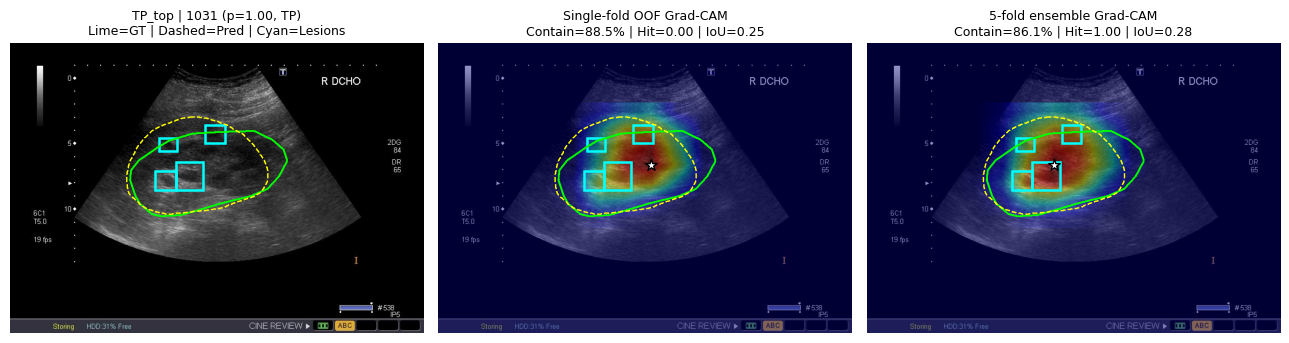

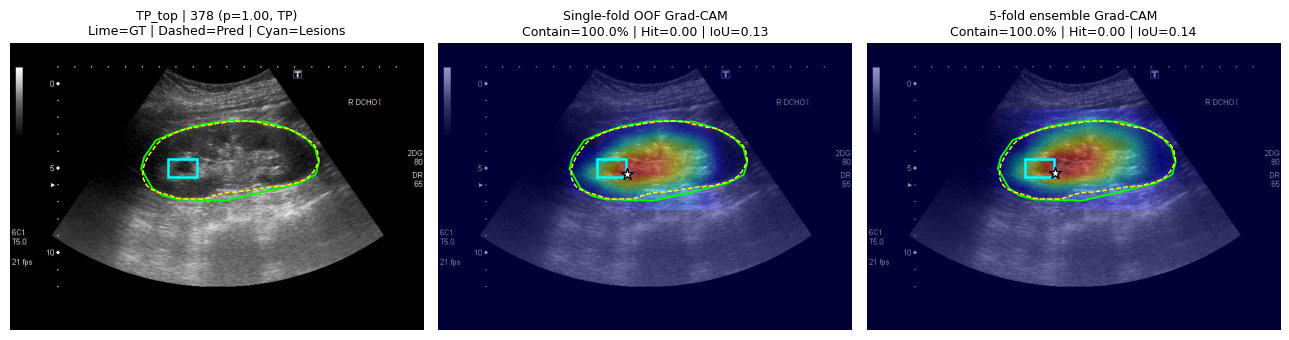

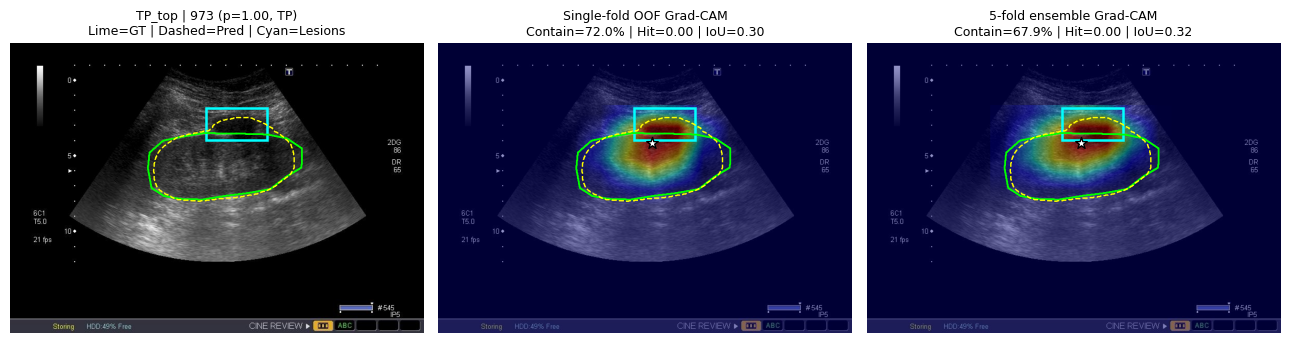

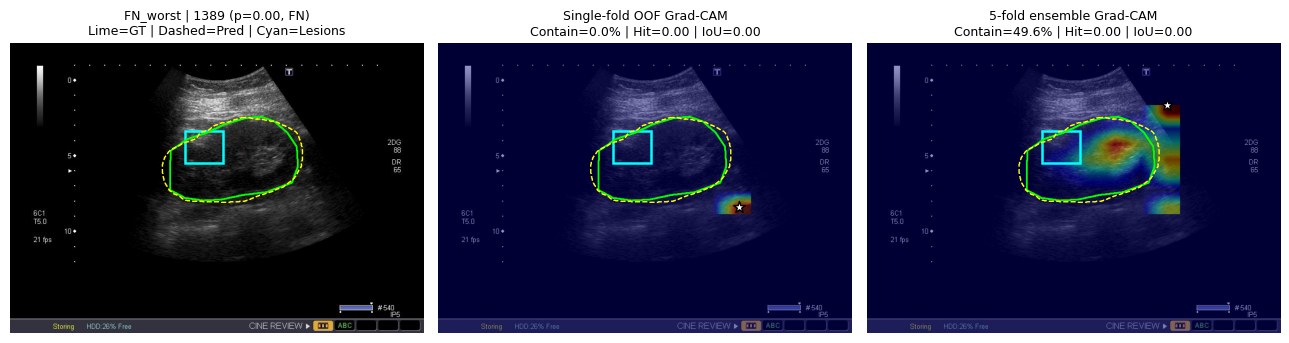

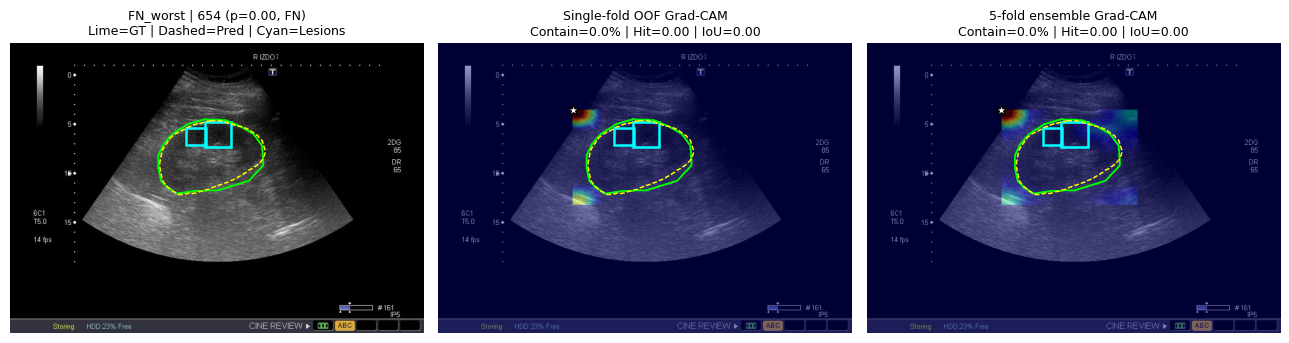

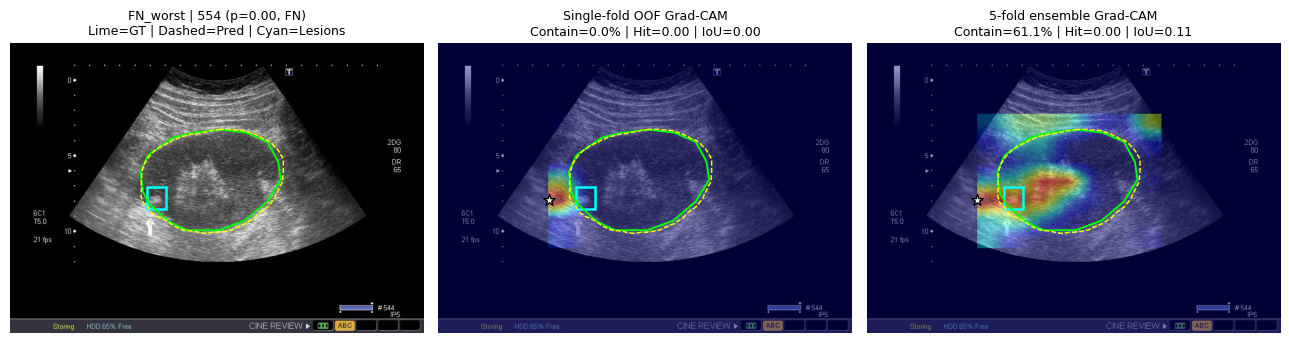

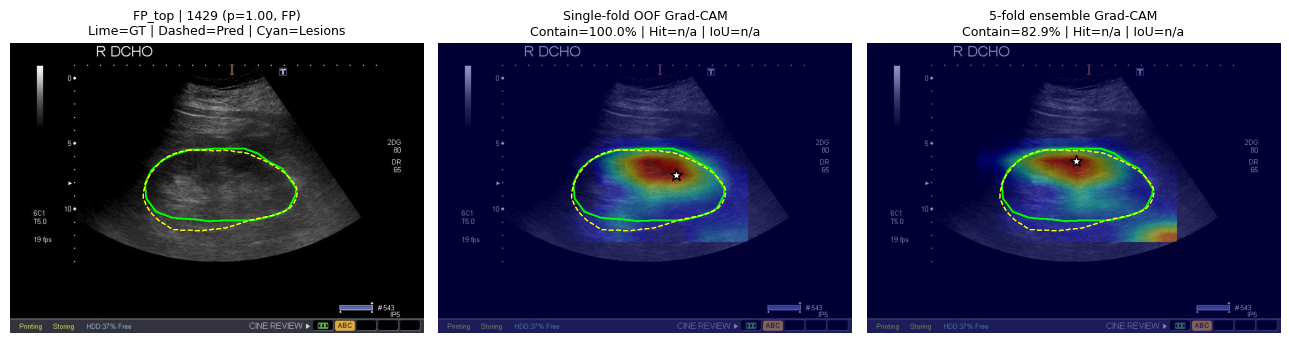

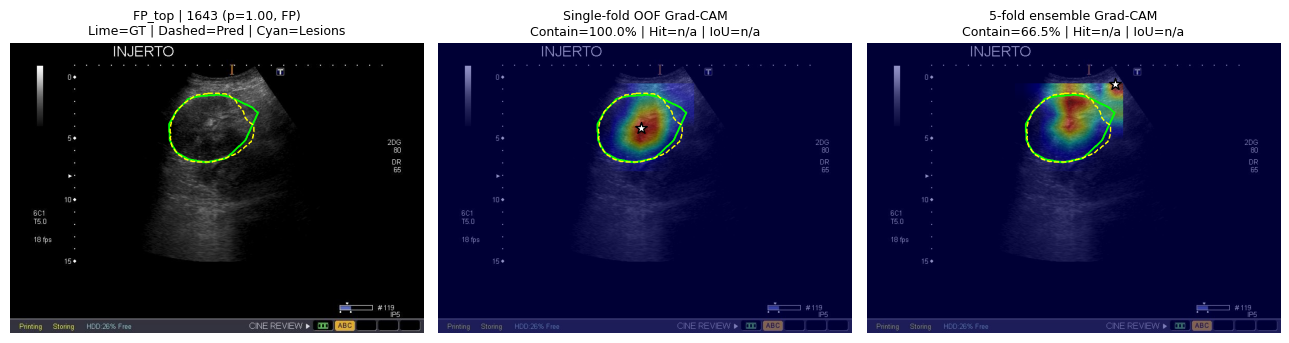

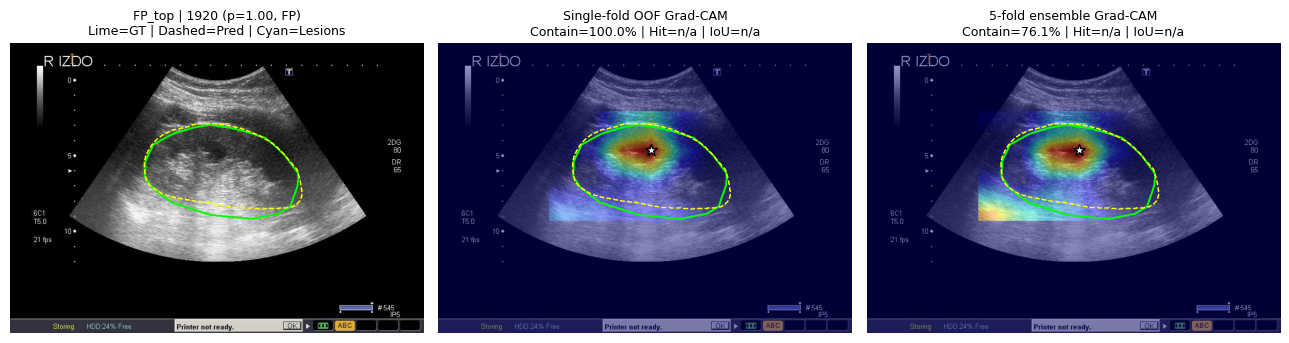

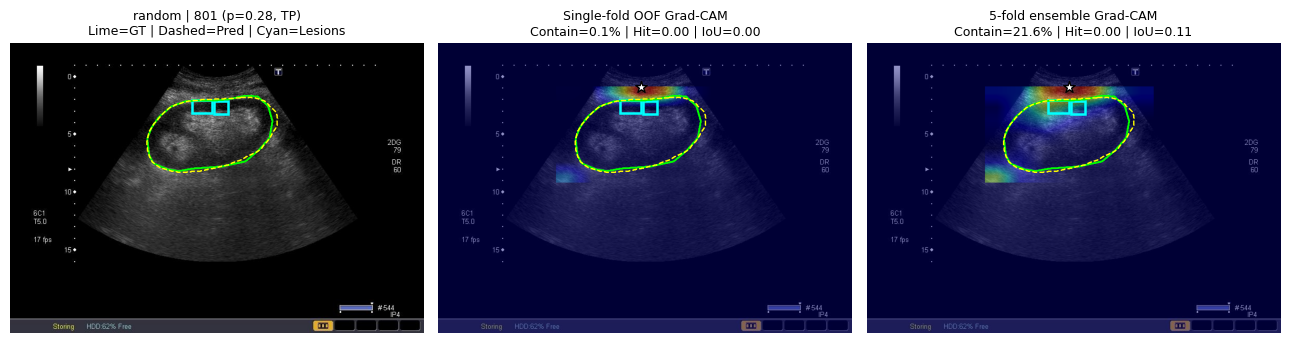

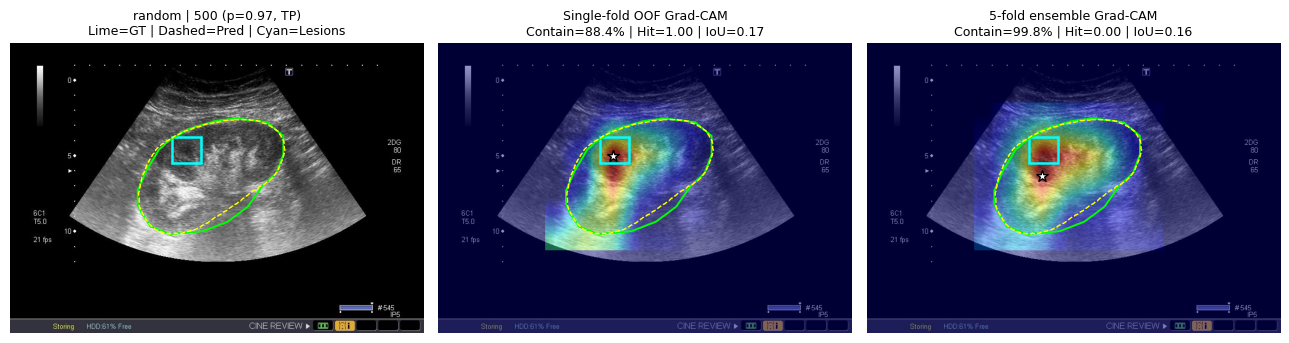

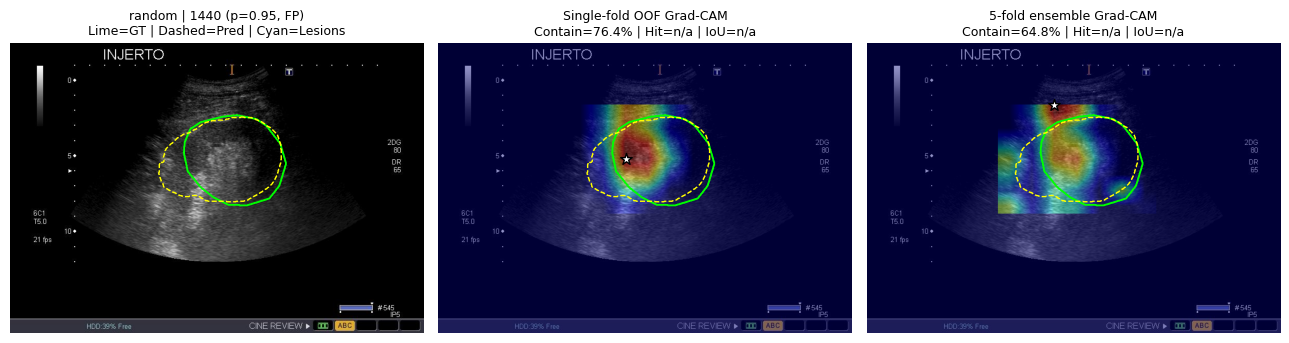

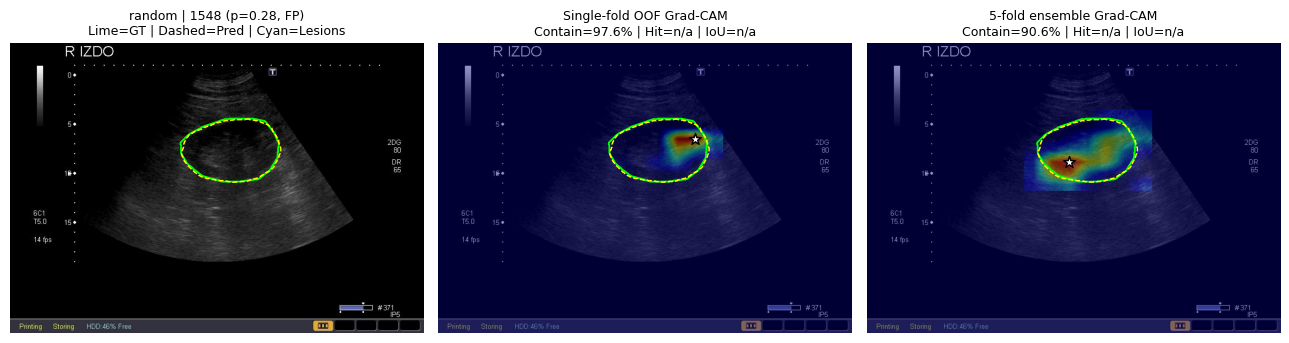

All Phase 3 deliverables saved in: /content/drive/MyDrive/Phase 3/results/phase3_xai


In [11]:
rng = np.random.default_rng(0)
tp = xai_img_df[(xai_img_df.outcome == 'TP') & (xai_img_df.n_boxes > 0)].sort_values('probability', ascending=False)
fn = xai_img_df[(xai_img_df.outcome == 'FN') & (xai_img_df.n_boxes > 0)].sort_values('probability')
fp = xai_img_df[xai_img_df.outcome == 'FP'].sort_values('probability', ascending=False)
rand = xai_img_df.sample(4, random_state=0)

selection = ([('TP_top', i) for i in tp.head(3).image_id] + [('FN_worst', i) for i in fn.head(3).image_id] +
             [('FP_top', i) for i in fp.head(3).image_id] + [('random', i) for i in rand.image_id])

crop_idx = crop_stats.set_index('image_id')


def fmt(v, pct=False, digits=1):
    if pd.isna(v):
        return 'n/a'
    return f'{v * 100:.{digits}f}%' if pct else f'{v:.2f}'


for tag, iid in selection:
    idx = xai_img_df.index[xai_img_df['image_id'] == iid][0]
    r = xai_img_df.loc[idx]
    img_rgb = np.asarray(Image.open(IMAGES_DIR / f'{iid}.jpg').convert('RGB'))
    gt_mask = sio.loadmat(GT_MASKS_DIR / f'{iid}.mat')['mask'] > 0
    pred_mask = np.asarray(Image.open(PRED_MASKS_DIR / f'{iid}.png').convert('L')) > 0
    H, W = gt_mask.shape
    _, boxes = parse_lesion_boxes(iid)
    boxes = clip_boxes(boxes, H, W)
    x0, y0, x1, y1 = crop_idx.loc[iid, ['crop_x0', 'crop_y0', 'crop_x1', 'crop_y1']].astype(int)

    cam_s = project_cam_to_full_image(all_cams[int(r.fold)][idx], (H, W), x0, y0, x1, y1)
    cam_e = project_cam_to_full_image(minmax(np.mean([all_cams[f][idx] for f in range(5)], axis=0)),
                                      (H, W), x0, y0, x1, y1)

    titles = [
        f'{tag} | {iid} (p={r.probability:.2f}, {r.outcome})\nLime=GT | Dashed=Pred | Cyan=Lesions',
        f'Single-fold OOF Grad-CAM\nContain={fmt(r.single_gt_bin_contain, True)} | Hit={fmt(r.single_pointing_hit_any)} | IoU={fmt(r.single_lesion_union_iou)}',
        f'5-fold ensemble Grad-CAM\nContain={fmt(r.ens_gt_bin_contain, True)} | Hit={fmt(r.ens_pointing_hit_any)} | IoU={fmt(r.ens_lesion_union_iou)}',
    ]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
    for ax, title, cam in zip(axes, titles, [None, cam_s, cam_e]):
        ax.imshow(img_rgb)
        ax.contour(gt_mask, colors='lime', linewidths=1.3)
        ax.contour(pred_mask, colors='yellow', linestyles='--', linewidths=1.0)
        for (bx0, by0, bx1, by1, cls) in boxes:
            ax.add_patch(plt.Rectangle((bx0, by0), bx1 - bx0, by1 - by0, fill=False, edgecolor='cyan', linewidth=1.8))
        if cam is not None:
            ax.imshow(cam, cmap='jet', alpha=0.42)
            yp, xp = np.unravel_index(np.argmax(cam), cam.shape)
            ax.scatter([xp], [yp], c='white', edgecolors='black', s=75, marker='*', zorder=6)
        ax.set_title(title, fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    fig.savefig(OUT_FIGS / f'{tag}_{iid}.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print(f'All Phase 3 deliverables saved in: {OUT_XAI}')